# Facial Expression Recognition – Image Prediction

This notebook **does NOT open the camera**. Select an image from your computer and the Teachable Machine model will predict the facial expression.

In [1]:
import sys
!{sys.executable} -m pip install tf-keras==2.21.0 pillow numpy

'c:\Program' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import os
import numpy as np
import tf_keras
from PIL import Image
from IPython.display import display

MODEL_PATH = os.path.join(os.getcwd(), "keras_model.h5")
LABELS_PATH = os.path.join(os.getcwd(), "labels.txt")

print("Model exists:", os.path.exists(MODEL_PATH))
print("Labels exist:", os.path.exists(LABELS_PATH))


Model exists: True
Labels exist: True


In [3]:
# Load Teachable Machine model and labels
model = tf_keras.models.load_model(MODEL_PATH, compile=False)

with open(LABELS_PATH, "r", encoding="utf-8") as f:
    class_names = [line.strip() for line in f if line.strip()]

print("Model loaded successfully.")
print("Classes:")
for label in class_names:
    print(label)



Model loaded successfully.
Classes:
0 Angry
1 Disgust
2 Fear
3 Happy
4 Neutral
5 sad
6 Surprised


Selected: C:/Users/Disha lukhi/Downloads/WhatsApp Image 2026-09-22 at 11.14.18 AM.jpeg


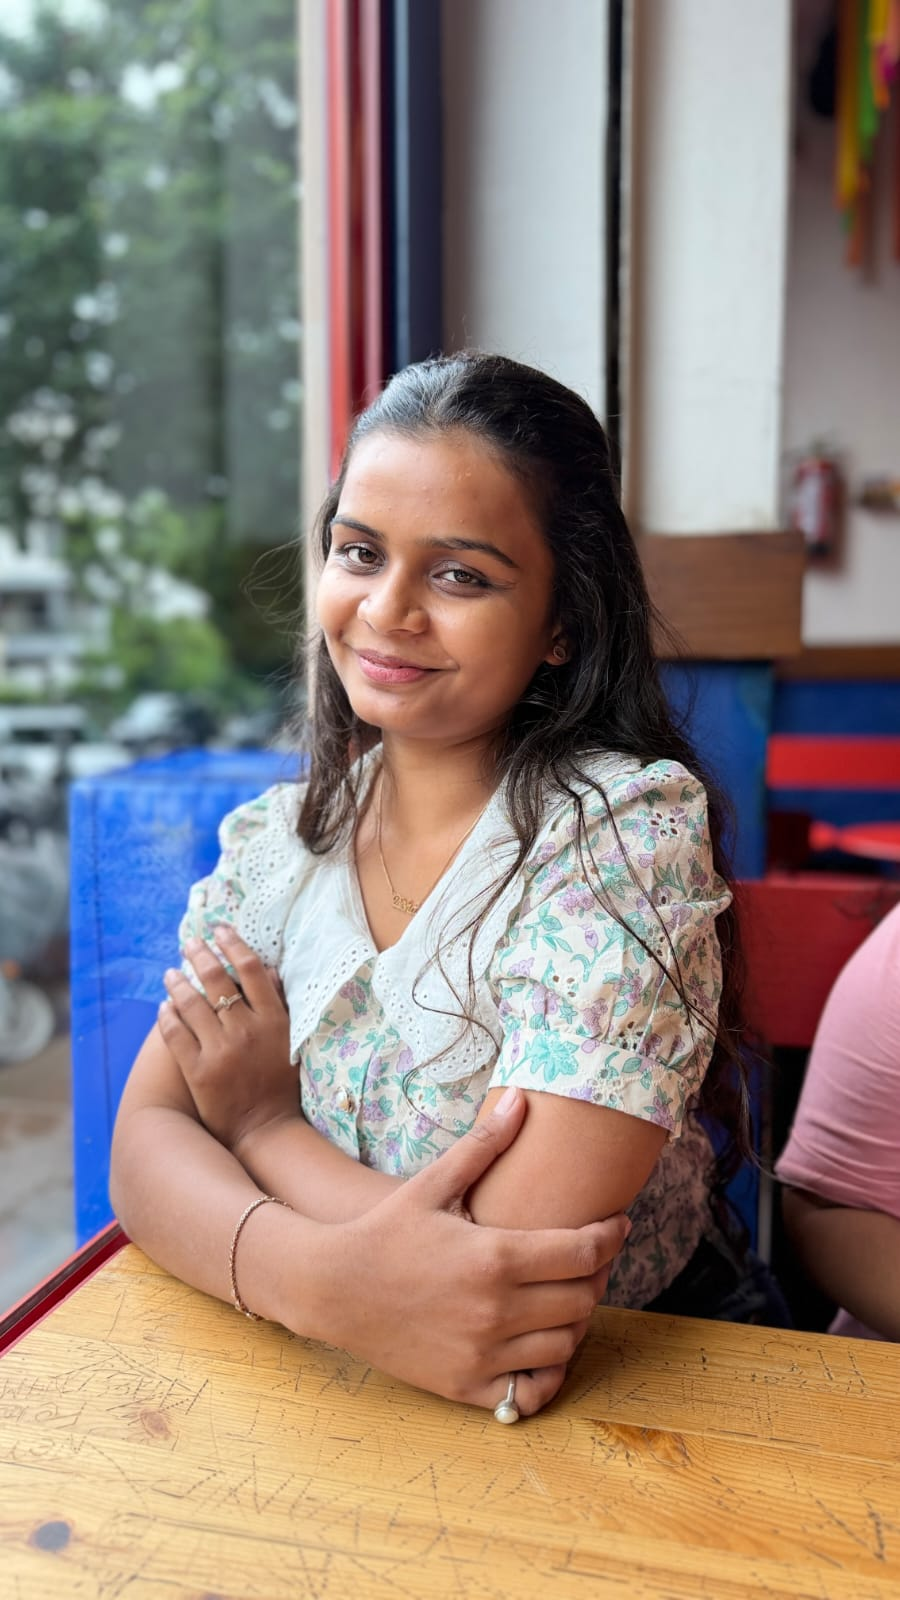

In [4]:
# Select an image — NO CAMERA
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes('-topmost', True)

image_path = filedialog.askopenfilename(
    title="Select Facial Expression Image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp *.webp"),
        ("All files", "*.*")
    ]
)
root.destroy()

if not image_path:
    print("No image selected.")
else:
    print("Selected:", image_path)
    original = Image.open(image_path).convert("RGB")
    display(original)

In [5]:
# Predict the selected image
if image_path:
    image = original.resize((224, 224))
    image_array = np.asarray(image, dtype=np.float32).reshape(1, 224, 224, 3)
    image_array = (image_array / 127.5) - 1.0

    prediction = model.predict(image_array, verbose=0)[0]
    index = int(np.argmax(prediction))
    confidence = float(prediction[index]) * 100

    class_name = class_names[index]
    if len(class_name) > 2 and class_name[0].isdigit() and class_name[1].isspace():
        class_name = class_name[2:].strip()

    print("==============================")
    print("Predicted Expression:", class_name)
    print(f"Confidence: {confidence:.2f}%")
    print("==============================")

Predicted Expression: Happy
Confidence: 60.96%


### Folder structure

```text
PR-4/
├── facial_expression_image.ipynb
├── keras_model.h5
└── labels.txt
```

**This notebook never uses `cv2.VideoCapture()` and does not open the webcam.**